In [1]:
import os, glob
import matplotlib.pyplot as plt
import scipy.io
import numpy as np
import pandas as pd

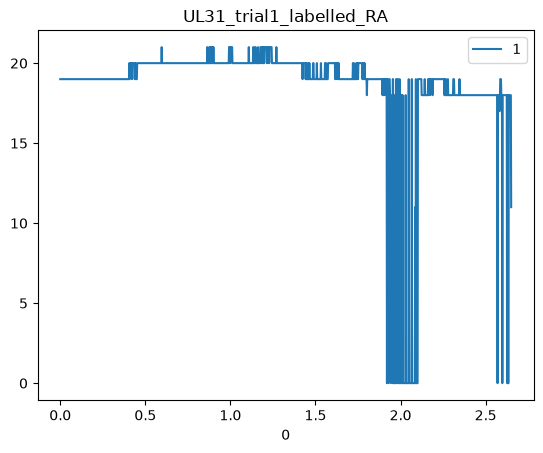

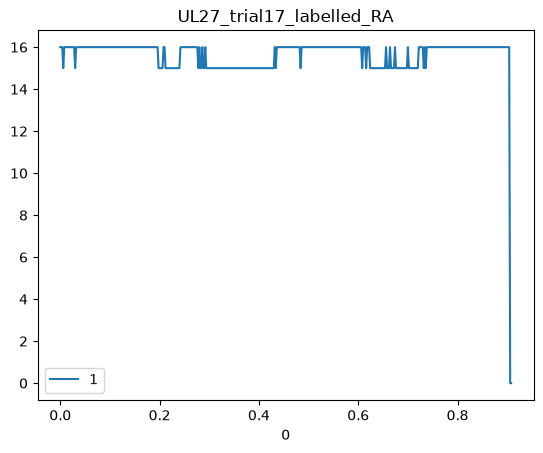

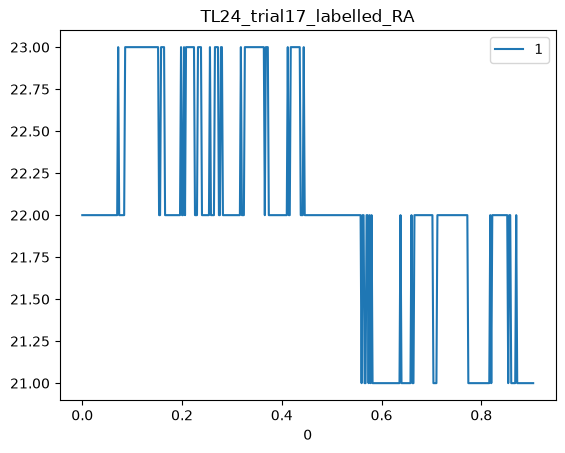

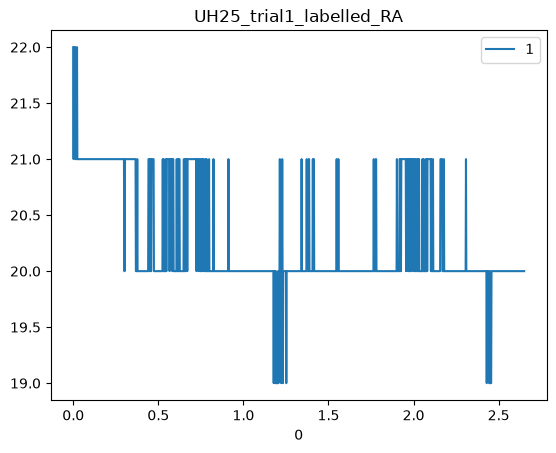

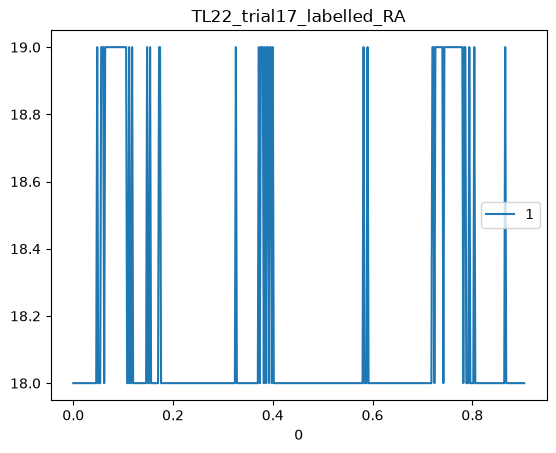

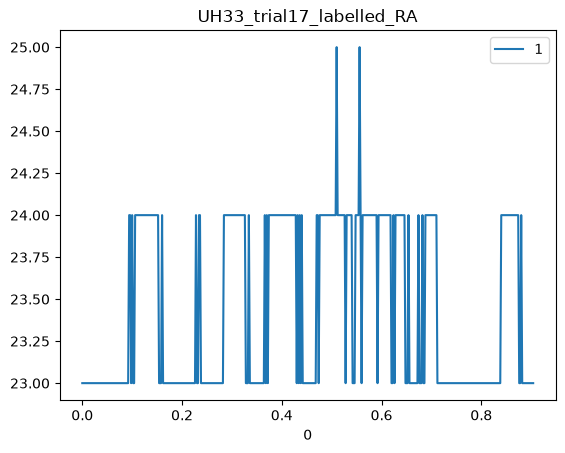

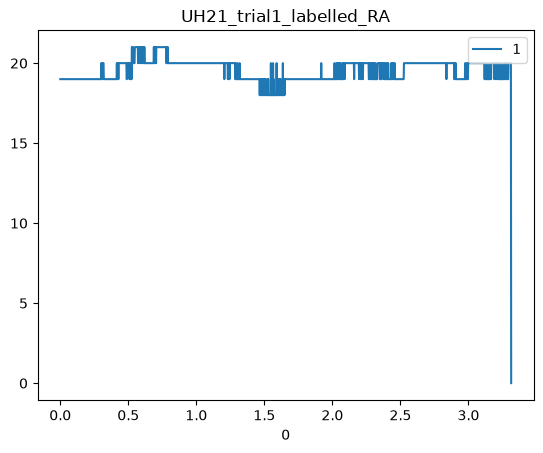

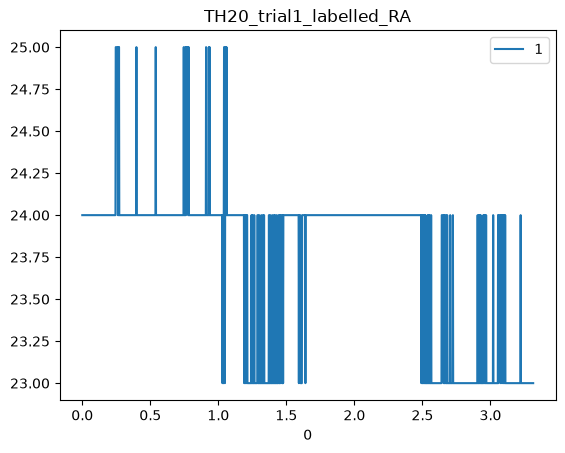

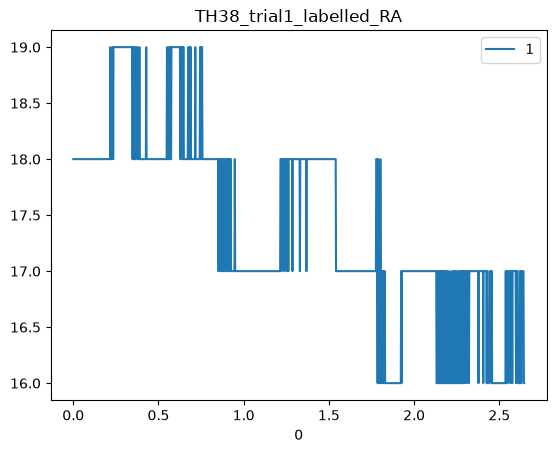

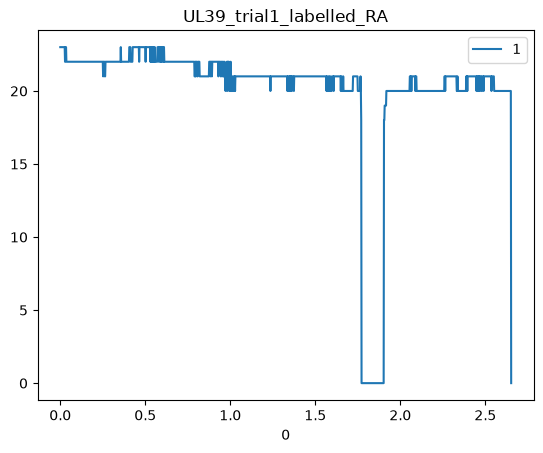

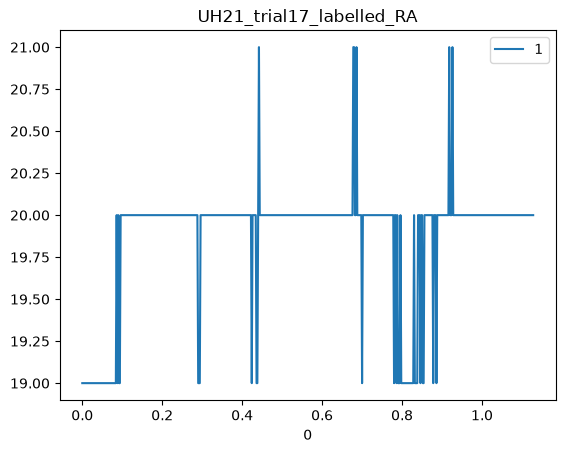

In [4]:
dirs_datas_RA = glob.glob(os.path.join(r"./EyeMovementDetectorEvaluation/annotated_data/data used in the article/dots", "*_labelled_RA.mat"))

for dir_datas_RA in dirs_datas_RA:
    mat_data = scipy.io.loadmat(dir_datas_RA)

    sampFreq = mat_data["ETdata"]["sampFreq"][0][0][0][0]
    viewDist = mat_data["ETdata"]["viewDist"][0][0][0][0]
    screenDim = mat_data["ETdata"]["screenDim"][0][0][0]
    screenRes = mat_data["ETdata"]["screenRes"][0][0][0]
    x_center, y_center = (screenRes-1)/2

    df_data = pd.DataFrame(mat_data["ETdata"]["pos"][0][0])
    df_data[0] = (1/sampFreq)*df_data.index 
    df_data[5] = df_data[5].astype('int64')

    df_data["pos_x"] = df_data[3] - x_center
    df_data["pos_y"] = df_data[4] - y_center

    df_data.plot(x=0, y=1)
    plt.title(os.path.basename(dir_datas_RA).replace(".mat", ""))
    plt.show()